# Lyrics vs. Audio Sentiment in Pop Music
### INFO 2950 Project, Phase II
**Group:** Yifan Niu and Avni Singh  
**GitHub repo:** https://github.com/avnisinghh/info2950

## Research questions

Our Phase 1 question was whether a song's audio valence (how happy it *sounds*) matches the sentiment of its lyrics, and whether that match changes across decades or genres. Professor Huang suggested two upgrades, which we adopted: (1) compute lyric sentiment ourselves with a sentiment library rather than relying on a single precomputed score, and (2) model the musical side from concrete features such as mode (major/minor), tempo, energy, and length, then compare our results against Spotify's valence score as a "ground truth."

Our updated research questions:

1. **Alignment.** How closely does a song's audio valence (Spotify) track the sentiment of its lyrics (computed by us with VADER)?
2. **Change over time and genre.** Has that alignment changed between 1965 and 2015, and does it differ by genre?
3. **What makes a song sound happy.** How well do interpretable musical features (major vs. minor mode, tempo, energy, danceability, loudness, acousticness, duration) predict Spotify's valence score, and does lyric sentiment add anything beyond those features?

Our **Unit of analysis** is one song that appeared on a Billboard *Year-End* Hot 100 chart between 1965 and 2015.

## Data collection and cleaning

### Data collection

**Change from Phase 1.** We planned to pull audio features from Spotify's Web API and scrape lyrics from Genius. When we started collecting, we found that Spotify restricted its `/audio-features` endpoint for new developer apps in November 2024; new apps receive a `403 Forbidden`. Since valence is the core variable of our project, we switched to two public datasets that were collected **before** that change. This also saves us from scraping thousands of Genius pages.

| File | What it contains | Source |
|---|---|---|
| `billboard_lyrics_1964-2015.csv` | 5,100 songs (100 per year, 1965–2015) from the Billboard Year-End Hot 100 with full lyrics, rank, artist, year | Kaylin Pavlik, [github.com/walkerkq/musiclyrics](https://github.com/walkerkq/musiclyrics). Song lists scraped from Wikipedia's year-end chart pages; lyrics scraped from metrolyrics.com (78.9%), songlyrics.com (15.7%), lyricsmode.com (1.8%) |
| `audio_features.csv` | 29,503 songs that ever appeared on the weekly Hot 100 (1958–2021) with Spotify audio features: valence, mode, tempo, energy, danceability, loudness, acousticness, duration, artist genres | Sean Miller via data.world, republished by [TidyTuesday 2021-09-14](https://github.com/rfordatascience/tidytuesday/tree/master/data/2021/2021-09-14). Pulled from the Spotify Web API |

Both files are downloaded by `collect_data.py` in our repo into `data/raw/`. The Billboard year-end list is our sampling frame: it gives a fixed 100 songs per year, which answers our Phase 1 reviewer's point about sampling the same number of songs per period.

**Combining the sources.** The two files share no ID, so we join on a normalized "song title + primary artist" key (details below). This merge is what lets us ask questions neither file answers alone: the lyrics file has no audio features, and the audio file has no lyrics.

In [1]:
# Setup
import ast, re, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

RAW, MID, CLEAN = Path("data/raw"), Path("data/intermediate"), Path("data/clean")
MID.mkdir(parents=True, exist_ok=True); CLEAN.mkdir(parents=True, exist_ok=True)
Path("figures").mkdir(exist_ok=True)

# One consistent color per measure across every figure
AUDIO, LYRIC, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "font.size": 10})
pd.set_option("display.precision", 3)

# Download the raw data into this folder if it isn't here yet
from pathlib import Path
from urllib.request import urlretrieve
Path("data/raw").mkdir(parents=True, exist_ok=True)
for f, u in {
    "billboard_lyrics_1964-2015.csv": "https://raw.githubusercontent.com/walkerkq/musiclyrics/master/billboard_lyrics_1964-2015.csv",
    "audio_features.csv": "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-09-14/audio_features.csv",
}.items():
    if not Path("data/raw", f).exists():
        urlretrieve(u, Path("data/raw", f))
print("data ready")

data ready


### Step 1: Load the raw files

In [2]:
# The lyrics file is latin-1 encoded (it fails to load as utf-8)
lyrics_raw = pd.read_csv(RAW / "billboard_lyrics_1964-2015.csv", encoding="latin-1")
audio_raw = pd.read_csv(RAW / "audio_features.csv")

print("lyrics file:", lyrics_raw.shape)
print("audio file: ", audio_raw.shape)
lyrics_raw.head(3)

lyrics file: (5100, 6)
audio file:  (29503, 22)


,Rank,Song,Artist,Year,Lyrics,Source
0,1,wooly bully,sam the sham and the pharaohs,1965,sam the sham miscellaneous wooly bully wooly b...,3.0
1,2,i cant help myself sugar pie honey bunch,four tops,1965,sugar pie honey bunch you know that i love yo...,1.0
2,3,i cant get no satisfaction,the rolling stones,1965,,1.0


### Step 2: Clean the lyrics file

- **We are dropping songs with missing or near-empty lyrics.** Pavlik's scraper could not find lyrics for some songs, and a few entries are only a handful of words (e.g., instrumentals). We keep songs with **at least 20 words**, since sentiment scores on a few words are not as meaningful.
- **Handle songs that charted in two year-end lists.** A song released late in one year can appear on two consecutive year-end charts. We keep its first appearance ONLY so each song is counted just once.

In [3]:
# Count words per song and then drop missing and very short lyrics
lyr = lyrics_raw.copy()
lyr["Lyrics"] = lyr["Lyrics"].fillna("").astype(str).str.strip()
lyr["word_count"] = lyr["Lyrics"].str.split().str.len()

n0 = len(lyr)
n_missing = (lyr["word_count"] == 0).sum()
n_short = ((lyr["word_count"] > 0) & (lyr["word_count"] < 20)).sum()
lyr = lyr[lyr["word_count"] >= 20]
print(f"start: {n0}  | missing lyrics: {n_missing}  | under 20 words: {n_short}  | kept: {len(lyr)}")

start: 5100  | missing lyrics: 234  | under 20 words: 38  | kept: 4828


### Step 3: Build a join key

The files format names differently ("Earth, Wind & Fire" vs. "earth wind and fire"; "Jay-Z + Alicia Keys" vs. "jayz featuring alicia keys"). We normalize both sides the same way:

- **Title:** strip accents, lowercase, drop anything in parentheses or brackets (e.g., *(From "Dirty Dancing")*), turn `&` into "and", remove punctuation, then remove spaces entirely (so "la la" and "lala" match).
- **Primary artist:** lowercase, keep only the part before a collaboration marker (*featuring, feat., with, duet with, &, and, +, x, vs.*, comma, slash), remove punctuation and a leading "the".

Splitting on commas and "and" also cuts band names like "Earth, Wind & Fire" down to "earth", but because we apply the identical rule to both files, the keys still line up.

In [4]:
# Normalize titles and artists so the two files can be joined
def _ascii_lower(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()

def norm_title(s):
    s = _ascii_lower(s)
    s = re.sub(r"\(.*?\)|\[.*?\]", "", s).replace("&", " and ")
    s = re.sub(r"[^a-z0-9]", "", s)        # drop punctuation AND spaces
    return s

COLLAB = r"\s(?:featuring|feat\.?|ft\.?|with|duet with|x|vs\.?|&|and|\+)\s|,|/"
def norm_artist(s):
    s = re.split(COLLAB, _ascii_lower(s))[0]
    s = re.sub(r"[^a-z0-9 ]", "", s).strip()
    s = re.sub(r"^the ", "", s)
    return re.sub(r"\s+", " ", s).strip()

lyr["title_key"], lyr["artist_key"] = lyr["Song"].map(norm_title), lyr["Artist"].map(norm_artist)

# Same song on two year-end charts -> keep the first year
n_before = len(lyr)
lyr = lyr.sort_values(["Year", "Rank"]).drop_duplicates(["title_key", "artist_key"], keep="first")
print(f"duplicate chart appearances removed: {n_before - len(lyr)}  | unique songs: {len(lyr)}")

# Quick check that the normalizer does what we expect
for raw in ["Earth, Wind & Fire", "Jay-Z + Alicia Keys", "The Honey Cone", "Kenny Rogers Duet With Dolly Parton"]:
    print(f"{raw:40s} -> {norm_artist(raw)}")

duplicate chart appearances removed: 199  | unique songs: 4629
Earth, Wind & Fire                       -> earth
Jay-Z + Alicia Keys                      -> jayz
The Honey Cone                           -> honey cone
Kenny Rogers Duet With Dolly Parton      -> kenny rogers


### Step 4: Clean the audio file

About 5,000 songs in the audio file have **no Spotify features at all** (the original collector could not find the track on Spotify). These rows cannot be used, so we drop them before matching. We also save this intermediate file.

In [5]:
# Keep only songs that have Spotify features, build the same join keys, and save
aud = audio_raw.dropna(subset=["valence"]).copy()
print(f"audio rows with features: {len(aud)} of {len(audio_raw)}")

aud["title_key"], aud["artist_key"] = aud["song"].map(norm_title), aud["performer"].map(norm_artist)
aud["artist_first"] = aud["artist_key"].str.split().str[0]
lyr["artist_first"] = lyr["artist_key"].str.split().str[0]

keep_cols = ["song_id", "song", "performer", "spotify_genre", "spotify_track_duration_ms",
             "spotify_track_explicit", "danceability", "energy", "key", "loudness", "mode",
             "speechiness", "acousticness", "instrumentalness", "liveness", "valence", "tempo",
             "time_signature", "title_key", "artist_key", "artist_first"]
aud = aud[keep_cols]
aud.to_csv(MID / "audio_with_features.csv", index=False)

audio rows with features: 24334 of 29503


### Step 5: Merge the two sources

1. Exact match on title key + primary-artist key.
2. Fallback match for songs still unmatched: title key + the first word of the artist (catches "kenny rogers duet with dolly parton" vs. "kenny rogers"). We will only accept a fallback when that pair is unique in the audio file.

We deliberately do not match on title alone. Many titles have cover versions in the audio file (e.g., Glee Cast's "Empire State of Mind" has Spotify features, while the Jay-Z original does not), and a title-only match would attach the wrong recording's audio.

In [6]:
# 1) exact
exact_pool = aud.drop_duplicates(["title_key", "artist_key"])
m = lyr.merge(exact_pool.drop(columns="artist_first"), on=["title_key", "artist_key"], how="left")
m["match_type"] = np.where(m["valence"].notna(), "exact", None)

# 2) fallback on title + first artist word, only where that pair is unique
fb_pool = aud.drop_duplicates(["title_key", "artist_first"], keep=False).drop(columns="artist_key")
unmatched = m[m["match_type"].isna()][lyr.columns]
fb = unmatched.merge(fb_pool, on=["title_key", "artist_first"], how="inner")
fb["match_type"] = "fallback"

merged = pd.concat([m[m["match_type"] == "exact"], fb], ignore_index=True)
merged.to_csv(MID / "merged_raw.csv", index=False)

print(f"exact matches:    {(merged.match_type == 'exact').sum()}")
print(f"fallback matches: {(merged.match_type == 'fallback').sum()}")
print(f"total matched:    {len(merged)} of {len(lyr)} unique songs ({len(merged)/len(lyr):.1%})")

# Hand-check a sample of fallback matches: lyrics-side vs audio-side names
fb[["Song", "Artist", "song", "performer"]].sample(8, random_state=2)

exact matches:    3826
fallback matches: 166
total matched:    3992 of 4629 unique songs (86.2%)


/var/folders/7s/mzgchfyx7vv5ln069n8x5sb00000gp/T/ipykernel_40992/2581408400.py:12: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  merged = pd.concat([m[m["match_type"] == "exact"], fb], ignore_index=True)


,Song,Artist,song,performer
42,bridge over troubled water,simon garfunkel,Bridge Over Troubled Water,Simon & Garfunkel
23,aint no mountain high enough,marvin gaye tammi terrell,Ain't No Mountain High Enough,Marvin Gaye & Tammi Terrell
44,which way you goin billy,the poppy family,Which Way You Goin' Billy?,The Poppy Family (Featuring Susan Jacks)
156,red dirt road,brooks dunn,Red Dirt Road,Brooks & Dunn
13,homeward bound,simon garfunkel,Homeward Bound,Simon & Garfunkel
3,save your heart for me,gary lewis the playboys,Save Your Heart For Me,Gary Lewis And The Playboys
6,laugh at me,sonny bono,Laugh At Me,Sonny
153,halfcrazy,musiq soulchild,halfcrazy,Musiq


We read through a sample of fallback matches by hand (above) to confirm they pair the same recording.

As for who got left out, we save the unmatched songs and check whether the match rate is even across decades. If one era were much less likely to match, our decade comparisons would be skewed. We also compare average chart rank, since unmatched songs could be systematically less popular.

In [7]:
# Flag which lyrics-file songs found a match, save the unmatched list, and check match rate by decade
lyr["matched"] = lyr.set_index(["title_key", "artist_key"]).index.isin(
    merged.set_index(["title_key", "artist_key"]).index)
lyr[~lyr["matched"]][["Year", "Rank", "Song", "Artist"]].to_csv(MID / "unmatched_songs.csv", index=False)

print("mean chart rank, matched:   {:.1f}".format(lyr.loc[lyr.matched, "Rank"].mean()))
print("mean chart rank, unmatched: {:.1f}".format(lyr.loc[~lyr.matched, "Rank"].mean()))
match_by_decade = (lyr.assign(decade=(lyr.Year // 10) * 10)
                     .groupby("decade")["matched"].agg(songs="size", match_rate="mean"))
match_by_decade

mean chart rank, matched:   50.5
mean chart rank, unmatched: 49.2


,songs,match_rate
decade,,
1960,456,0.864
1970,910,0.841
1980,952,0.876
1990,885,0.825
2000,897,0.885
2010,529,0.898


### Step 6: Score lyric sentiment ourselves

**Why not just plain VADER?** VADER's `compound` score sums the sentiment of every word and squashes the total into [-1, 1]. That works for tweets, but a song has hundreds of words, so the score pins to the extremes. When we tried it on our data, and about two-thirds of songs scored above +0.95 or below -0.95, which leaves almost no variation to analyze.

**Our approach.** The lyrics come lowercased with no punctuation or line breaks, so we cannot split by line. Instead we split each song into consecutive 12-word windows (roughly one sung line), score each window with VADER, and average them. The result, `lyric_vader`, stays in [-1, 1] but spreads songs out.

**Second measure as a check.** We also compute TextBlob polarity (`lyric_textblob`), a different lexicon-based method. If the two are able to agree, we are  more confident our measure captures something real (this addresses our Phase 1 question for reviewers about whether a simple tool is good enough).

In [8]:
# Score lyrics three ways: plain VADER (to show saturation), windowed VADER (ours), TextBlob
vader = SentimentIntensityAnalyzer()

def vader_full(text):
    return vader.polarity_scores(text)["compound"]

def vader_windowed(text, n=12):
    words = text.split()
    windows = [" ".join(words[i:i + n]) for i in range(0, len(words), n)]
    return float(np.mean([vader.polarity_scores(w)["compound"] for w in windows]))

merged["lyric_vader_full"] = merged["Lyrics"].map(vader_full)        # kept only to show the problem
merged["lyric_vader"] = merged["Lyrics"].map(vader_windowed)
merged["lyric_textblob"] = merged["Lyrics"].map(lambda t: TextBlob(t).sentiment.polarity)

saturated = (merged["lyric_vader_full"].abs() > 0.95).mean()
print(f"plain VADER: {saturated:.0%} of songs score beyond +/-0.95")
print(f"windowed VADER: {(merged['lyric_vader'].abs() > 0.95).mean():.0%} of songs beyond +/-0.95")

plain VADER: 68% of songs score beyond +/-0.95
windowed VADER: 0% of songs beyond +/-0.95


### Step 7: Create analysis variables

- `year`, `decade` (1960s = 1965–69 only; 2010s = 2010–15).
- `major` = 1 if Spotify's `mode` is major, 0 if minor.
- `duration_min` = track length in minutes.
- `genre`: Spotify lists genres per artist (like `['dance pop', 'pop', 'post-teen pop']`). We collapse these into six broad buckets by keyword, checked in priority order so that, e.g., "country rock" counts as Country and "pop rap" as Hip-hop: Hip-hop/Rap → Country → R&B/Soul → Rock → Pop → Other'. Artists with no listed genre become "Unknown".
- Standardized (z-score) versions of valence and lyric sentiment so the two can share an axis in trend plots.

In [9]:
# Keyword rules for collapsing Spotify artist genres into broad buckets (checked in this order)
GENRE_RULES = [
    ("Hip-hop/Rap", ["hip hop", "rap", "trap", "drill", "crunk"]),
    ("Country",     ["country", "bluegrass"]),
    ("R&B/Soul",    ["r&b", "soul", "funk", "disco", "motown", "quiet storm", "new jack", "doo-wop"]),
    ("Rock",        ["rock", "metal", "punk", "grunge", "new wave", "alternative", "indie"]),
    ("Pop",         ["pop", "adult standards", "easy listening", "dance"]),
]

def broad_genre(raw):
    try:
        tags = ast.literal_eval(raw) if isinstance(raw, str) else []
    except (ValueError, SyntaxError):
        tags = []
    if not tags:
        return "Unknown"
    joined = " | ".join(tags)
    for label, words in GENRE_RULES:
        if any(w in joined for w in words):
            return label
    return "Other"

df = merged.rename(columns={"Year": "year", "Rank": "rank", "Song": "title", "Artist": "artist"})
df["decade"] = (df["year"] // 10) * 10
df["major"] = df["mode"].astype(int)
df["duration_min"] = df["spotify_track_duration_ms"] / 60000
df["genre"] = df["spotify_genre"].map(broad_genre)
df["valence_z"] = (df["valence"] - df["valence"].mean()) / df["valence"].std()
df["lyric_z"] = (df["lyric_vader"] - df["lyric_vader"].mean()) / df["lyric_vader"].std()

FINAL_COLS = ["year", "decade", "rank", "title", "artist", "genre", "match_type", "word_count",
              "lyric_vader", "lyric_textblob", "lyric_z", "valence", "valence_z", "major",
              "tempo", "energy", "danceability", "loudness", "acousticness", "speechiness",
              "instrumentalness", "duration_min", "spotify_track_explicit", "spotify_genre"]
df = df[FINAL_COLS].sort_values(["year", "rank"]).reset_index(drop=True)
df.to_csv(CLEAN / "songs_analysis_ready.csv", index=False)
print(df.shape)
df.head()

(3992, 24)


,year,decade,rank,title,artist,genre,match_type,word_count,lyric_vader,lyric_textblob,...,tempo,energy,danceability,loudness,acousticness,speechiness,instrumentalness,duration_min,spotify_track_explicit,spotify_genre
0,1965,1960,1,wooly bully,sam the sham and the pharaohs,Rock,exact,125,-0.405,-0.102,...,140.601,0.575,0.582,-11.890,0.713,0.053,3.660e-06,2.348,False,"['brill building pop', 'bubblegum pop', 'class..."
1,1965,1960,4,you were on my mind,we five,Rock,exact,152,-0.195,-0.156,...,143.381,0.565,0.510,-8.105,0.485,0.050,0.000e+00,2.599,False,"['bubblegum pop', 'folk rock']"
2,1965,1960,5,youve lost that lovin feelin,the righteous brothers,R&B/Soul,exact,232,0.106,0.112,...,94.791,0.305,0.369,-14.303,0.522,0.027,0.000e+00,3.774,False,"['adult standards', 'brill building pop', 'bub..."
3,1965,1960,6,downtown,petula clark,Rock,exact,239,0.103,0.331,...,117.409,0.689,0.480,-7.921,0.780,0.065,0.000e+00,3.129,False,"['adult standards', 'brill building pop', 'bub..."
4,1965,1960,7,help,the beatles,Rock,exact,228,0.178,-0.071,...,95.003,0.725,0.534,-7.576,0.188,0.033,0.000e+00,2.326,False,"['british invasion', 'merseybeat', 'psychedeli..."


### Cleaning summary

The table below traces every row from the raw lyrics file to the analysis-ready dataset, so the full pipeline can be checked at a glance.

In [10]:
# Row counts at each cleaning step (raw lyrics file -> analysis-ready data)
funnel = pd.DataFrame({
    "step": ["Raw Billboard year-end lyrics file (1965-2015)",
             "Drop songs with missing lyrics",
             "Drop songs with fewer than 20 words",
             "Drop repeat appearances on a second year-end chart",
             "Drop songs with no matching Spotify audio features",
             "Analysis-ready dataset"],
    "rows removed": pd.array([None, n_missing, n_short, n_before - len(lyr), len(lyr) - len(df), None], dtype="Int64"),
    "rows remaining": [n0, n0 - n_missing, n0 - n_missing - n_short, len(lyr), len(df), len(df)],
})
funnel

,step,rows removed,rows remaining
0,Raw Billboard year-end lyrics file (1965-2015),<NA>,5100
1,Drop songs with missing lyrics,234,4866
2,Drop songs with fewer than 20 words,38,4828
3,Drop repeat appearances on a second year-end c...,199,4629
4,Drop songs with no matching Spotify audio feat...,637,3992
5,Analysis-ready dataset,<NA>,3992


## Data description

*Structured based on the five question groups in Gebru et al. (2018), "Datasheets for Datasets," sections 3.1–3.5. We are answering every question that applies to our analysis ready data and note where one does not apply.*

### 3.1 Motivation

**For what purpose was the dataset created?** To test whether the emotion a pop song sounds like (Spotify valence) matches the emotion its lyrics express, whether that match level has changed from 1965 to 2015, and which musical features determine how happy a song sounds. No existing dataset pairs lyric sentiment with audio features for a consistent sample of hits, so we built one by merging two sources.

**Who created it, and who funded it?** Our INFO 2950 group (Yifan Niu & Avni Singh) built the merged dataset, as an unfunded project for our Data Science class. The sources were also volunteer efforts: Kaylin Pavlik compiled the lyrics for a personal blog analysis, and Sean Miller compiled the Spotify features and posted them on data.world, where the TidyTuesday project republished them for data visualization practice. Neither source lists funding as far as we could find.

### 3.2 Composition

**What do the instances represent, and how many are there?** Each row is one song from a Billboard Year-End Hot 100 chart (1965–2015) that has at least 20 words of lyrics and matched Spotify audio features. There are 3992 songs and 24 columns in `data/clean/songs_analysis_ready.csv`:

| Group | Columns |
|---|---|
| Chart info | `year`, `decade`, `rank` (1–100 on that year's chart), `title`, `artist` |
| Lyric sentiment (computed by us) | `lyric_vader` (windowed VADER, −1 to 1), `lyric_textblob` (−1 to 1), `lyric_z`, `word_count` |
| Spotify audio (from source) | `valence` (0 = sad/angry sounding, 1 = happy/cheerful), `major` (1 = major mode), `tempo` (BPM), `energy`, `danceability`, `acousticness`, `speechiness`, `instrumentalness` (all 0–1), `loudness` (dB), `duration_min`, `spotify_track_explicit` |
| Genre | `genre` (our 7 buckets), `spotify_genre` (Spotify's raw artist-level tags) |
| Bookkeeping | `match_type` (exact or fallback join), `valence_z` |

**Is it a sample, and of what?** It is a sample of the most commercially successful U.S. singles: every year-end song we could score and match. It's not representative of all music released, of non-U.S. music, or of what listeners liked independent of label promotion and radio play. Songs are missing when lyrics or Spotify features were unavailable, and we check whether those losses are biased in Step 5.

**What data does each instance consist of?** Features, not raw text or audio. We do not keep the lyrics in the analysis-ready file, only scores computed from them.

**Is there a label or target?** No label was assigned by the creators. In our analyses, Spotify `valence` serves as the outcome variable (the "ground truth" for how happy a song sounds).

**Is information missing from individual instances?** No row in the analysis-ready file has a missing core value. Missingness happens at the song level instead (songs dropped for no lyrics or no match); the dropped songs are listed in `data/intermediate/unmatched_songs.csv`.

**Are relationships between instances explicit?** Only implicitly: songs share artists, years, and genres. Songs by the same artist are not independent observations, which matters for later modeling.

**Are there recommended data splits?** None from the sources. If we evaluate a predictive model, we will use a random train/test split with a fixed seed.

**Are there errors, noise, or redundancies?** Yes. Lyrics were scraped by lyrics-site URL patterns, so some may belong to the wrong song or contain transcription errors and nonstandard spellings (e.g., "nite" for "night"). A fallback join could pair a song with the wrong recording, and we hand checked a sample. Songs on two year-end charts were deduplicated.

**Is the dataset self-contained?** No, as it depends on two external GitHub-hosted files with no guarantee of permanence, so we keep copies in our repo. Spotify features can no longer be re-pulled because Spotify closed the endpoint. Song lyrics are copyrighted, and we use them only to compute aggregate scores and do not redistribute full lyrics in our report.

**Confidential, offensive, or sensitive content?** There is nothing confidential, but some lyrics contain profanity, slurs, and sexual or violent content, which is why we never display full lyrics. Because the songs are written by people, the data relates to people: artists are public figures identifiable by name, and genre tags can act as a proxy for artists' race or ethnicity (see Limitations). There is no personal data such as locations, finances, or health information.

### 3.3 Collection process

**How was the data acquired?** Chart positions, titles, and lyrics are *directly observable* public text. Spotify valence, energy, danceability, and mode are derived by Spotify's proprietary audio models and cannot be verified. Our lyric scores are derived by us with VADER and TextBlob; we validated them only partially by checking that the two methods agree (Figure 2).

**What mechanisms were used?** Pavlik used R (`xml`, `RCurl`) to scrape song lists from Wikipedia's year-end chart pages, then lyrics from metrolyrics.com (78.9%), songlyrics.com (15.7%), and lyricsmode.com (1.8%); about 3.6% of songs had no lyrics found. Miller pulled audio features from the Spotify Web API. We downloaded both files with `collect_data.py` and processed them in Python (pandas, vaderSentiment, textblob).

**Sampling strategy?** *Deterministic*: every song on each year-end chart, about 100 per year. This gives a near-equal number of songs per year, as suggested in our Phase 1 feedback.

**Who collected it, and over what timeframe?** The upstream creators collected the data; we did the merge and scoring for coursework. The songs were released and charted between 1965 and 2015, but the Spotify features were measured decades later (republished in September 2021), potentially on remastered versions rather than the original audio samples.

**Ethical review, notice, and consent?** There's no IRB review - this is public, published media with no human subjects. Artists were not notified and did not consent to their lyrics being scraped, which is a reason we only analyze aggregate scores.

### 3.4 Preprocessing, cleaning, and labeling

**Was preprocessing done?** Upstream, Pavlik lowercased the lyrics and removed punctuation and line breaks. We removed missing and short lyrics, removed duplicate chart appearances, dropped audio rows without features, normalized names, merged the files, scored sentiment, and derived `decade`, `major`, `genre`, and z-scores (Steps 1–7 and the cleaning summary table).

**Was the raw data saved?** Yes. The unmodified source files are in `data/raw/`, and intermediate files are in `data/intermediate/`.

- Lyrics: https://github.com/walkerkq/musiclyrics/blob/master/billboard_lyrics_1964-2015.csv
- Audio features: https://github.com/rfordatascience/tidytuesday/blob/master/data/2021/2021-09-14/audio_features.csv
- Our copies plus all processed files: https://github.com/avnisinghh/info2950 (`data/`)

**Is the software available?** Yes. `collect_data.py` and this notebook in our repo reproduce every step from the raw files.

### 3.5 Uses

**Has the data been used already?** The lyrics file has. Pavlik analyzed word use across 50 years of hits on her blog, and Brand, Acerbi & Mesoudi (2019) analyzed 4,913 songs from 1965–2015, which matches this file's 5,100 songs minus its 187 without lyrics, to study rising negativity in lyrics. The audio file was used in many TidyTuesday visualizations. Our merged dataset has not been used before.

**What other tasks could it support?** Studying how tempo, mode, or explicit content in hits changed over the years is one task, but comparing sentiment tools on song lyrics or exploring what features distinguish higher and lower ranked hits are also potential uses.

**Could its composition affect future uses?** Yes: English sentiment lexicons tend to score profanity and African American English as more negative, so genre comparisons could unfairly portray hip-hop and R&B lyrics as darker than other genres. The sample covers only U.S. commercial hits. Anyone using this data should treat genre-level sentiment differences cautiously.

**What should it not be used for?** Generally, making assumptions like individual artists' emotional content or mental state, or making claims about listeners' moods or mental health, or generalizing to all music or non-English music.

**Credit.** Lyrics compiled by Kaylin Pavlik (walkerkq); Spotify features compiled by Sean Miller (data.world) and shared by the R for Data Science TidyTuesday project; audio features originally produced by Spotify (The Echo Nest). Our dataset exists because of their work!

## Data limitations

**1. Spotify valence is a black box.** Spotify never published how valence is computed as it is a proprietary model's prediction. We are treating it as "ground truth" for how happy a song sounds, but it is really just one company's estimate. Not everyone may agree on the valence of the song. If Spotify's model partly relies on cues correlated with lyrics (for example, vocal tone), our alignment estimates would be inflated.

**2. Our lyric sentiment measure is crude.** Dictionary methods like VADER and TextBlob score words one at a time. They miss sarcasm, irony, and context, and pop lyrics are full of slang. "I'm so happy I could die," or a breakup song that repeats "love" in every line, can score positive. The source lyrics also have no punctuation or capitalization, which VADER normally uses to judge intensity. Our 12-word windows are a practical fix for saturation, not a validated method. Any weak relationship we find could partly reflect measurement error on the lyrics side rather than true mismatch.

**3. The match is not random.** We lose roughly 15% of songs in the merge, mostly songs with no Spotify features. If missing songs are systematically different (e.g., older, less-streamed, or by artists with unusual name formats), our sample over-represents songs that stayed popular enough to be on Spotify. Our checks in Step 5 are reassuring in two ways: match rates are similar across decades (83%–90%), and unmatched songs have about the same average chart rank as matched ones (49 vs. 51). But they could still differ in ways we did not measure, such as genre or whether the original recording is on streaming at all.

**4. Genre is assigned to artists, not songs.** Spotify tags *artists* with genres. A rock band's ballad gets labeled Rock. Our keyword buckets are also our own judgment call - a different rule set could move songs between genres. Genre results should be read as approximations.

**5. Recordings may differ.** The Spotify features describe whichever version the collector found, which could be a remaster, re-recording, or live version, while chart positions refer to the original single.

**6. Decades are uneven at the edges, and charts have changed.** The 1960s include only 1965–69 and the 2010s only 2010–15. Billboard's methodology also changed (digital sales, streaming), so "change over time" mixes changes in music with changes in which music charts.

**7. Lyrics are English-centric.** VADER and TextBlob are built for English. Songs with non-English lyrics (e.g., "Macarena," "Despacito"-style hits) will get near-neutral scores that do not reflect their content as it is in a language VADER/TextBlob cannot make use of.

**How this could affect meaning and people.** The main risk is over-interpreting a null or weak result as "musicians write sad lyrics over happy music" when it may come from noisy measurement. In the other direction, a headline finding like "pop got sadder" can feed broad cultural claims (about youth, mental health, or particular genres) that this data cannot support. Because hip-hop and R&B are disproportionately made by Black artists, genre comparisons using English sentiment lexicons - which are known to score African American English and profanity as more negative - could produce misleading conclusions about those genres. We will frame genre results cautiously and report them with this caveat.

## Exploratory data analysis (EDA)

We keep this analysis focused on what our questions need: (1) do our two core variables have usable distributions, (2) does our lyric measure hold up, (3) what do the two variables look like together, over time, and by genre, and (4) how do the musical features relate to valence. We intentionally do not fit the regression models here, those will be preregistered in Part 2.

### Summary statistics

In [11]:
# Summary statistics for the variables our research questions use
core = ["valence", "lyric_vader", "lyric_textblob", "major", "tempo", "energy",
        "danceability", "loudness", "acousticness", "duration_min", "word_count"]
df[core].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

,count,mean,std,min,25%,50%,75%,max
valence,3992.0,0.609,0.237,3.820e-02,0.427,0.634,0.808,0.986
lyric_vader,3992.0,0.136,0.187,-5.803e-01,0.012,0.121,0.251,0.823
lyric_textblob,3992.0,0.116,0.178,-7.012e-01,0.000,0.113,0.235,0.805
major,3992.0,0.695,0.461,0.000e+00,0.000,1.000,1.000,1.000
tempo,3992.0,119.196,27.062,3.671e+01,99.017,117.785,132.835,210.750
energy,3992.0,0.633,0.188,2.040e-02,0.498,0.651,0.783,0.997
danceability,3992.0,0.626,0.148,1.490e-01,0.532,0.639,0.729,0.980
loudness,3992.0,-8.408,3.516,-2.549e+01,-10.744,-7.876,-5.645,-1.101
acousticness,3992.0,0.235,0.241,1.510e-05,0.037,0.145,0.369,0.988
duration_min,3992.0,4.011,1.032,4.948e-01,3.428,3.926,4.475,26.019


In [12]:
# Songs per decade and per genre (sample balance)
pd.concat([df["decade"].value_counts().sort_index().rename("songs per decade")], axis=1).T

,1960,1970,1980,1990,2000,2010
songs per decade,394,765,834,730,794,475


In [13]:
# Songs per genre bucket
df["genre"].value_counts().rename("songs").to_frame().T

,Rock,R&B/Soul,Hip-hop/Rap,Pop,Country,Unknown,Other
songs,1405,839,720,424,374,152,78


### Figure 1: Distributions of our two core variables

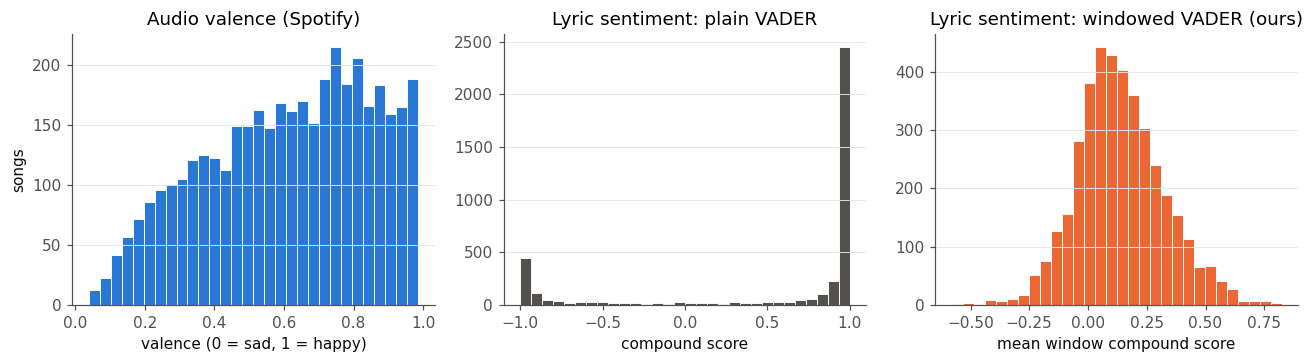

In [14]:
# Histograms: Spotify valence, plain VADER (to show saturation), and our windowed VADER
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(df["valence"], bins=30, color=AUDIO, edgecolor="white", linewidth=0.6)
axes[0].set(title="Audio valence (Spotify)", xlabel="valence (0 = sad, 1 = happy)", ylabel="songs")

axes[1].hist(merged["lyric_vader_full"], bins=30, color=MUTED, edgecolor="white", linewidth=0.6)
axes[1].set(title="Lyric sentiment: plain VADER", xlabel="compound score")

axes[2].hist(df["lyric_vader"], bins=30, color=LYRIC, edgecolor="white", linewidth=0.6)
axes[2].set(title="Lyric sentiment: windowed VADER (ours)", xlabel="mean window compound score")
for ax in axes: ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("figures/fig1_distributions.png", bbox_inches="tight"); plt.show()

**Takeaways.** Spotify valence covers the full 0–1 range with a lean toward happier-sounding songs (median 0.63), which makes sense for chart hits. Plain VADER (middle) is unusable: about 68% of songs land at the ±1 extremes, confirming the saturation problem. Our windowed version (right) is roughly bell-shaped, centered slightly positive (median 0.12), with real spread in both directions. 

**Decision:** we use windowed VADER as our lyric measure.

### Figure 2: Does our lyric measure hold up? (VADER vs. TextBlob)

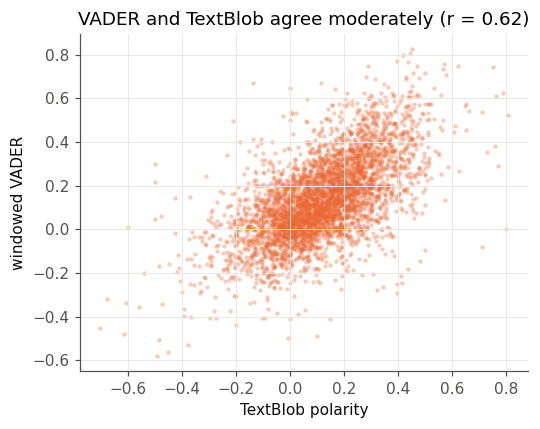

Pearson r = 0.618, Spearman rho = 0.611


In [15]:
# Agreement between our two lyric sentiment methods
r_methods = df["lyric_vader"].corr(df["lyric_textblob"])
rho_methods = df["lyric_vader"].corr(df["lyric_textblob"], method="spearman")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(df["lyric_textblob"], df["lyric_vader"], s=8, alpha=0.35, color=LYRIC, linewidths=0)
ax.set(xlabel="TextBlob polarity", ylabel="windowed VADER",
       title=f"VADER and TextBlob agree moderately (r = {r_methods:.2f})")
plt.tight_layout(); plt.savefig("figures/fig2_method_agreement.png", bbox_inches="tight"); plt.show()
print(f"Pearson r = {r_methods:.3f}, Spearman rho = {rho_methods:.3f}")

**Takeaways.** The two lyric methods agree moderately (r ≈ 0.62). That is high enough to suggest both capture something real about lyric tone, but low enough that the choice of method could matter. 

**Decision:** windowed VADER stays primary (it handles negation like "don't love you" better than TextBlob), and we will rerun our main analyses with TextBlob as a check for robustness.

### Figure 3: Audio valence vs. lyric sentiment

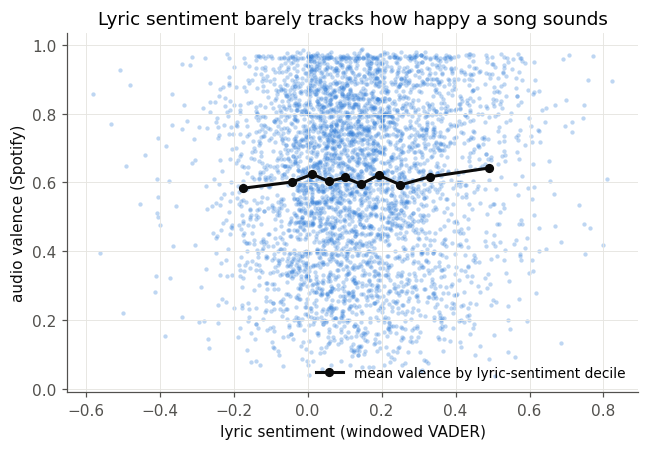

valence vs VADER:    Pearson r = 0.046, Spearman rho = 0.044
valence vs TextBlob: Pearson r = 0.031


In [16]:
# Song-level relationship between audio valence and lyric sentiment
r_main = df["valence"].corr(df["lyric_vader"])
rho_main = df["valence"].corr(df["lyric_vader"], method="spearman")
r_tb = df["valence"].corr(df["lyric_textblob"])

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(df["lyric_vader"], df["valence"], s=8, alpha=0.3, color=AUDIO, linewidths=0)
# binned means to show the average trend without fitting a model
bins = pd.qcut(df["lyric_vader"], 10)
bm = df.groupby(bins, observed=True).agg(x=("lyric_vader", "mean"), y=("valence", "mean"))
ax.plot(bm["x"], bm["y"], color=INK, linewidth=2, marker="o", markersize=5, label="mean valence by lyric-sentiment decile")
ax.set(xlabel="lyric sentiment (windowed VADER)", ylabel="audio valence (Spotify)",
       title="Lyric sentiment barely tracks how happy a song sounds")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig3_valence_vs_lyrics.png", bbox_inches="tight"); plt.show()
print(f"valence vs VADER:    Pearson r = {r_main:.3f}, Spearman rho = {rho_main:.3f}")
print(f"valence vs TextBlob: Pearson r = {r_tb:.3f}")

**Takeaways:** This is our most important exploratory result. At the song level, lyric sentiment and audio valence are almost unrelated (Pearson r ≈ 0.05, Spearman ρ ≈ 0.04; TextBlob gives r ≈ 0.03). The decile means (black line) are nearly flat: songs with the most negative lyrics average a valence around 0.59, the most positive around 0.64. Every combination is common, including very sad-sounding songs with upbeat lyrics and vice versa.

This fits our Phase 1 feedback that a weak or null relationship is still meaningful. It also means the interesting questions are conditional: whether any link survives once we account for musical features and time, and whether the link was stronger in some eras than others. These conditional questions, rather than the simple correlation, are what our preregistered models in Part 2 will target.

### Figure 4: How have sound and lyrics changed over time?

Both measures are z-scored (0 = the 1965–2015 average) so they can share one axis. Shaded bands are 95% confidence intervals for the yearly mean. The right panel checks our data against a published finding: Schellenberg & von Scheve (2012) reported that the share of Top 40 hits in a major key fell sharply from the 1960s to the 2000s.

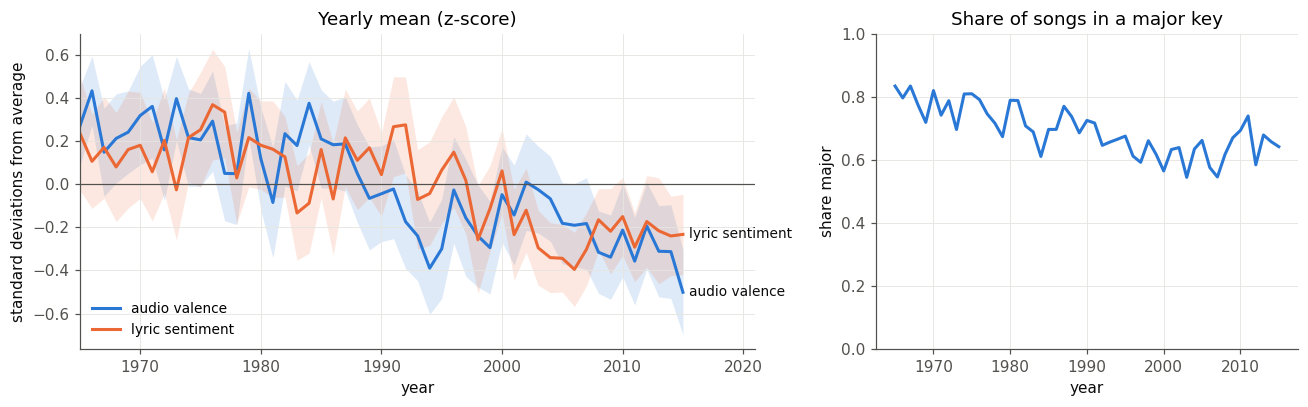

        valence  lyric_vader  major    tempo
decade                                      
1960      0.672        0.164  0.794  119.283
1970      0.667        0.170  0.758  118.365
1980      0.642        0.151  0.717  121.004
1990      0.565        0.143  0.660  116.994
2000      0.574        0.091  0.610  117.763
2010      0.534        0.095  0.665  123.070


In [17]:
# Yearly means with 95% CIs for valence and lyric sentiment, plus share of major-key songs
def yearly(col):
    g = df.groupby("year")[col]
    mean, se = g.mean(), g.std() / np.sqrt(g.size())
    return mean, mean - 1.96 * se, mean + 1.96 * se

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for col, color, label in [("valence_z", AUDIO, "audio valence"), ("lyric_z", LYRIC, "lyric sentiment")]:
    m_, lo, hi = yearly(col)
    axes[0].fill_between(m_.index, lo, hi, color=color, alpha=0.15, linewidth=0)
    axes[0].plot(m_.index, m_, color=color, linewidth=2, label=label)
    axes[0].annotate(label, (m_.index[-1], m_.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                     color=INK, fontsize=9, va="center")
axes[0].axhline(0, color=MUTED, linewidth=0.8)
axes[0].set(title="Yearly mean (z-score)", xlabel="year", ylabel="standard deviations from average", xlim=(1965, 2021))
axes[0].legend(frameon=False, loc="lower left", fontsize=9)

maj = df.groupby("year")["major"].mean()
axes[1].plot(maj.index, maj, color=AUDIO, linewidth=2)
axes[1].set(title="Share of songs in a major key", xlabel="year", ylabel="share major", ylim=(0, 1))
plt.tight_layout(); plt.savefig("figures/fig4_trends.png", bbox_inches="tight"); plt.show()

print(df.groupby("decade")[["valence", "lyric_vader", "major", "tempo"]].mean().round(3))

**Takeaways.**
- **Both measures decline together.** Yearly average valence fell from about 0.67 in the 1960s–70s to 0.53 in the 2010s, and average lyric sentiment fell from about 0.16 to 0.10. The lyric decline matches Brand, Acerbi & Mesoudi (2019), who found rising negativity in this same 1965–2015 Billboard lyrics corpus.
- **A key contrast with Figure 3:** the two measures track each other closely **across years** even though they barely relate **across individual songs**. Pop as a whole got both sadder-sounding and sadder-worded, but within a given year, a song's words tell you very little about its sound. We should be careful not to read the year-level pattern as a song-level one.
- **Our data replicate a published trend, which supports its validity.** The share of songs in a major key fell from about 79% in the 1960s to about 61% in the 2000s. Schellenberg & von Scheve (2012) reported the same direction with a steeper drop in Top 40 data; the gap may reflect their different song sample and how mode was coded (they coded by ear, while Spotify detects it algorithmically).

### Figure 5: Differences by genre

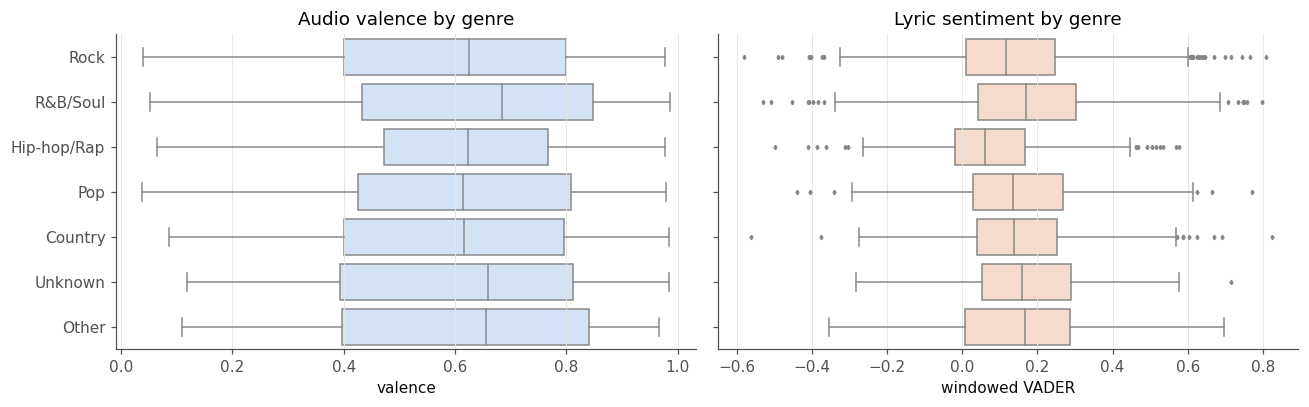

,songs,valence,lyric_vader,r_valence_lyrics
genre,,,,
Rock,1405,0.601,0.131,0.045
R&B/Soul,839,0.634,0.176,0.003
Hip-hop/Rap,720,0.605,0.072,0.086
Pop,424,0.606,0.149,0.028
Country,374,0.593,0.155,0.045
Unknown,152,0.613,0.167,0.096
Other,78,0.619,0.165,0.075


In [18]:
# Boxplots of each core measure by genre, largest genre first, plus a per-genre summary table
order = df["genre"].value_counts().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
sns.boxplot(data=df, y="genre", x="valence", order=order, ax=axes[0], color="#cde2fb",
            fliersize=2, linewidth=1)
axes[0].set(title="Audio valence by genre", xlabel="valence", ylabel="")
sns.boxplot(data=df, y="genre", x="lyric_vader", order=order, ax=axes[1], color="#fbd9c8",
            fliersize=2, linewidth=1)
axes[1].set(title="Lyric sentiment by genre", xlabel="windowed VADER", ylabel="")
plt.tight_layout(); plt.savefig("figures/fig5_genre.png", bbox_inches="tight"); plt.show()

df.groupby("genre").agg(songs=("valence", "size"), valence=("valence", "mean"),
                        lyric_vader=("lyric_vader", "mean"),
                        r_valence_lyrics=("valence", lambda s: s.corr(df.loc[s.index, "lyric_vader"]))
                        ).loc[order].round(3)

**Takeaways.** Average valence is similar across genres (0.59–0.63). Lyric sentiment differs more: **Hip-hop/Rap has the lowest average lyric score (0.07)**, about half that of R&B/Soul (0.18). We are cautious about this gap: VADER scores profanity and some slang as negative, so part of it may be a lexicon artifact rather than genuinely darker lyrics (see Limitation 7 and our harms note). Within every genre, the valence–lyrics correlation is weak (r = 0.00 to 0.10), so the weak overall link is not driven by one genre. **Decision:** genre stays a secondary variable; "Unknown" and "Other" (230 songs combined) are too small and mixed to interpret on their own.

### Figure 6: Which musical features move with valence?

This is the setup for RQ3. We look at simple pairwise correlations between Spotify valence and each candidate feature, plus correlations among the features themselves, to spot predictors that overlap so much they would be redundant in one model.

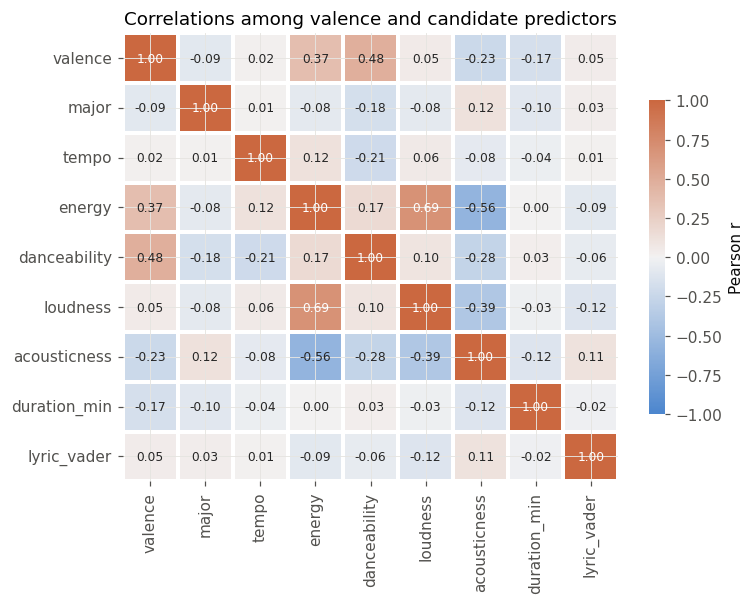

Mean valence: major = 0.596, minor = 0.640


In [19]:
# Correlation matrix: valence vs. each candidate predictor, and predictors vs. each other
feats = ["valence", "major", "tempo", "energy", "danceability", "loudness", "acousticness",
         "duration_min", "lyric_vader"]
corr = df[feats].corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, cmap=sns.diverging_palette(250, 25, s=75, l=55, as_cmap=True), center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1.5,
            linecolor="white", cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set(title="Correlations among valence and candidate predictors")
plt.tight_layout(); plt.savefig("figures/fig6_feature_corr.png", bbox_inches="tight"); plt.show()

print("Mean valence: major = {:.3f}, minor = {:.3f}".format(
    df.loc[df.major == 1, "valence"].mean(), df.loc[df.major == 0, "valence"].mean()))

**Takeaways.**
- **Danceability (r = 0.48) and energy (r = 0.37) have the strongest links to valence.** Acousticness (-0.23) and duration (−0.17) are negative; tempo and loudness are close to zero on their own.
- **Surprise: major-key songs have *slightly lower* average valence than minor-key songs (0.60 vs. 0.64, r = −0.09).** This contradicts the standard music-psychology link between major mode and happiness. One likely explanation is confounding: minor-key songs in our data are more danceable (0.67 vs. 0.61) and energetic, and Hip-hop/Rap songs, which are often danceable, are minor about half the time (vs. 15% for Country). Whether major mode predicts higher valence once danceability and energy are held constant is an open question for our models.
- **Energy, loudness, and acousticness overlap heavily** (energy <-> loudness r = 0.69, energy <-> acousticness r = −0.56). This is important for modeling: putting all three in one regression could make their individual coefficients unstable.

### What the EDA changed

- **Research questions:** RQ1 stays, but the near-zero raw correlation shifted our focus from "is there a link?" to "does any link survive controls, and did it change over time?" RQ3 gained a sharper target: whether major mode predicts valence once confounds are held constant.
- **Lyric measure:** we switched from plain VADER to windowed VADER after finding saturation, and added TextBlob as a robustness check.
- **Time:** we will model year as continuous rather than comparing decades, since the 1960s and 2010s are partial and the trends look gradual rather than stepwise.
- **Sample:** match rates are similar across decades (83%–90%) and unmatched songs are no less popular on average, so dropping them should not badly skew time comparisons.
- **Data description:** updated to reflect our switch from the Spotify API to archived datasets, and the final sample of 3,992 songs.

## Questions for reviewers

1. **Lyric measure.** Windowed VADER and TextBlob agree only moderately. Should we make one primary and report the other as a robustness check, average them, or hand-label a random sample of ~50 songs (positive/neutral/negative) to see which one tracks human judgment better?
2. **Decade balance.** Following Phase 1 feedback, the year-end chart gives about 100 songs per year, but 1965–69 and 2010–15 are partial decades. Is it better to model year as continuous (our current plan), or to drop the partial decades and compare four full decades (1970s–2000s)?
3. **Genre buckets.** Spotify genre tags belong to artists, not songs, and we bucket them by keyword. Is this defensible for a secondary analysis, or should we limit genre comparisons to the three largest buckets?
4. **Collinear features.** Energy, loudness, and acousticness are strongly correlated (Figure 6). When we build the multivariable model Professor Huang suggested, should we keep all three, drop one or two, or combine them into a single "intensity" index?
5. **Ground truth.** Professor Huang suggested treating Spotify valence as ground truth. Given that valence is itself a black-box prediction (Limitation 1), is it reasonable to evaluate our feature-based model by how well it reproduces valence on held-out songs, or is there a better benchmark we should use?

## References

- Brand, C. O., Acerbi, A., & Mesoudi, A. (2019). Cultural evolution of emotional expression in 50 years of song lyrics. *Evolutionary Human Sciences, 1*, e11.
- Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2018). Datasheets for datasets. *arXiv:1803.09010*.
- Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of ICWSM*.
- Schellenberg, E. G., & von Scheve, C. (2012). Emotional cues in American popular music: Five decades of the Top 40. *Psychology of Aesthetics, Creativity, and the Arts, 6*(3), 196–203.

# Part 2: Preregistration of Analyses

The hypotheses below follow from our research questions and from what our EDA in Part 1 found. We have **not** fit any of the regression models described here; the EDA only shows pairwise correlations and group means. We will run every analysis below and report the results in our final report whether or not they support our hypotheses.

**Notation and setup.** `valence` is Spotify audio valence (0 to 1) and is the outcome in every model. `lyric_vader` is our windowed-VADER lyric sentiment. `year_c` is release year centered at 1990, so year is treated as continuous, as planned in Part 1. All models are ordinary least squares regressions on the 3,992 songs in `songs_analysis_ready.csv`, and all tests use α = 0.05.

**One shared set of musical controls.** To keep the three analyses consistent, they all use the same controls: `danceability`, `energy`, `acousticness`, `major`, `tempo`, and `duration_min`. We leave out `loudness` because it overlaps heavily with `energy` (r = 0.69, Figure 6), and keeping both would make their individual coefficients unstable.

## Preregistration Statement 1: Lyric sentiment still predicts sound after controls, but adds very little (RQ1, RQ3)

**Hypothesis.** Holding musical features and year constant, songs with more positive lyrics will have **higher** audio valence (β_lyric > 0). We expect the effect to be **small**: adding lyric sentiment to a model of musical features will raise R² by **less than 0.01**.

**Reasoning.** Songwriters and producers usually aim for an emotionally coherent song, so we expect some positive link. But the raw correlation in our EDA was close to zero (r ≈ 0.05, Figure 3), and the features most tied to valence (danceability r = 0.48, energy r = 0.37) have nothing to do with the words. Spotify also computes valence from audio alone, so lyrics should explain little once the sound is accounted for.

**Analysis.**
- **Model A (music + time):** `valence ~ danceability + energy + acousticness + major + tempo + duration_min + year_c`
- **Model B (adds lyrics):** Model A + `lyric_vader`

We will run a one-sided t-test of whether β_lyric > 0 in Model B and report the coefficient with its 95% confidence interval. To test whether lyrics add anything beyond the music (the second half of RQ3), we will compare Models A and B with a nested-model F-test and report the change in R². **Robustness check:** we will refit Model B with `lyric_textblob` in place of `lyric_vader` and report whether the sign and significance agree.

## Preregistration Statement 2: The link between lyrics and sound has weakened over time (RQ2)

**Hypothesis.** The association between lyric sentiment and audio valence was **stronger in earlier years and weakened toward 2015**. In the model below, the interaction coefficient will be **negative** (β_interaction < 0).

**Reasoning.** Schellenberg & von Scheve (2012) found that Top 40 hits became more **emotionally ambiguous** over these decades, more often mixing happy and sad cues (for example, a fast tempo in a minor key). When the music itself sends mixed signals, it should match the words less closely. Our EDA fits this picture: the share of major-key songs fell from about 79% in the 1960s to 61% in the 2000s (Figure 4), while the song-level link between lyrics and sound is weak overall.

**Analysis.** We will fit:

`valence ~ lyric_vader + year_c + lyric_vader × year_c`

and run a one-sided t-test of whether β_interaction < 0. A negative interaction means the slope of valence on lyric sentiment gets flatter in later years. To make the result easy to interpret, we will also estimate the slope and Pearson correlation of valence on `lyric_vader` **separately within each decade** and show them with 95% confidence intervals in one table and one plot. We will label 1965–69 and 2010–15 as partial decades, since they have fewer songs and wider intervals.

## Preregistration Statement 3: Major mode predicts happier sound once confounds are controlled (RQ3)

**Hypothesis.** Holding the other musical features and year constant:
- songs in a **major key** will have **higher** valence than songs in a minor key (β_major > 0);
- **danceability** will be positively associated with valence (β_danceability > 0);
- **energy** will be positively associated with valence (β_energy > 0).

**Reasoning.** Music perception research consistently links major mode with happiness, and it was a central cue in Schellenberg & von Scheve (2012). Our EDA showed the **opposite raw pattern**: major-key songs average *lower* valence (0.60 vs. 0.64, r = −0.09). We think this is confounding, not a real reversal. Minor-key songs in our data are more danceable (0.67 vs. 0.61) and more energetic, and Hip-hop/Rap songs, which tend to be danceable, are in a minor key about half the time, compared with 15% for Country. If our reasoning is right, the sign of β_major will **flip from negative (raw) to positive (controlled)**. Danceability and energy had the strongest raw links to valence (Figure 6), and we expect those to hold under controls.

**Analysis.**
- We will use **Model A** from Statement 1 and run one-sided t-tests on β_major, β_danceability, and β_energy. We will report the adjusted β_major next to the raw major-minor difference so the sign flip, or the lack of one, is visible.
- **Ground-truth comparison (how well features predict valence).** Following Professor Huang's suggestion to compare our model against Spotify's score, we will fit Model A on a random 80% of songs (fixed random seed) and report R² and RMSE on the held-out 20%. This shows how much of Spotify's black-box valence score interpretable musical features can reproduce.

**A note on genre.** RQ2 also asks about genre, but we are not preregistering a genre hypothesis. Genre tags describe artists rather than songs (Limitation 4), and English sentiment lexicons may score hip-hop and R&B lyrics as more negative for reasons unrelated to their emotional content (Limitation 7). We will report genre differences descriptively, as in Figure 5.

## Questions for Reviewers

1. **Control variables.** We dropped `loudness` because of its overlap with `energy` (r = 0.69) but kept `energy` and `acousticness` together (r = −0.56). Is that reasonable, or should we check variance inflation factors before finalizing the model?
2. **Statistical vs. practical significance.** With almost 4,000 songs, even a tiny lyric effect may come out statistically significant in Statement 1. Is a ΔR² threshold (we chose 0.01) a good way to judge whether lyrics matter in practice, or would you suggest a different benchmark?
3. **Measuring change over time.** For Statement 2, is a year × lyric sentiment interaction the right test of "alignment weakened," or would a per-song mismatch score (|standardized valence − standardized lyric sentiment|) regressed on year be clearer?
4. **Genre as a control.** Since Hip-hop/Rap songs are more often in a minor key, should Statement 3 also control for genre, even though our genre labels are rough and artist-level?
5. **Songs by the same artist.** Many artists appear several times, so their songs are not fully independent. Should we use standard errors clustered by artist, or is ordinary OLS acceptable for this project?